# Dataset Analysis

## Libraries

In [16]:
import pandas as pd # Dataset loading
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np # Used in the mask for the corr. matrix

## Data Loading

In [17]:
full_df = pd.read_csv("./dataset.csv")
full_df["date"] = pd.to_datetime(full_df['date'], format='%Y-%m-%d')

df = full_df.drop(columns=["date", "longitude", "latitude", "fire"]) # These ones are not variables

## Correlation Matrix
---
Linear correlation between the numeric variables. Categorical variables are left out.

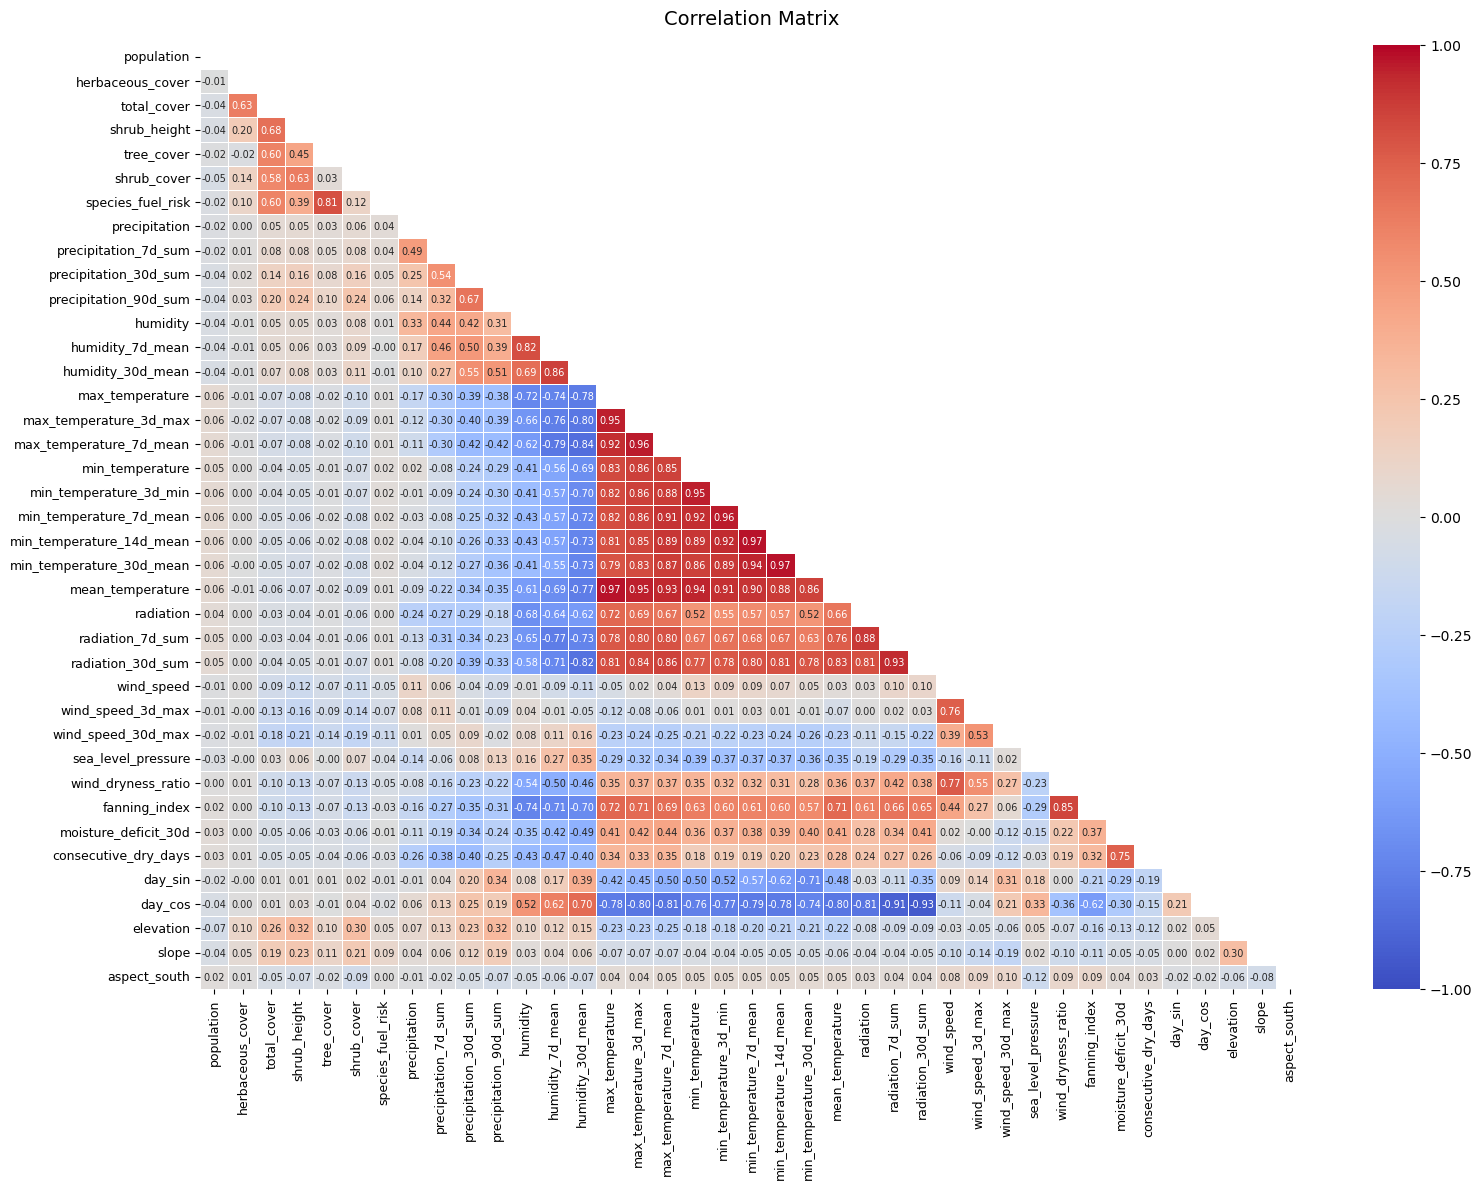

In [18]:
# Categorical variables are removed
categorical_cols = ["structure_type", "fuel_model", "biogeographic_region", "development_stage", "stand_distribution"]
categorical_cols += [col for col in df.columns if col.startswith("forest_type_")]

# Correlation matrix
corr = df.drop(columns=categorical_cols).corr(numeric_only=True)

# Upper triangle mask
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(16, 12))

# Heatmap for the correlation matrix
sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    annot_kws={"size": 7}
)

# Avoids label overlapping
plt.xticks(rotation=90, fontsize=9)
plt.yticks(rotation=0, fontsize=9)

plt.title("Correlation Matrix", fontsize=14, pad=15)

plt.tight_layout()
plt.show()

## Events Per Year
---
Number of positives (fires) and negatives of each year.

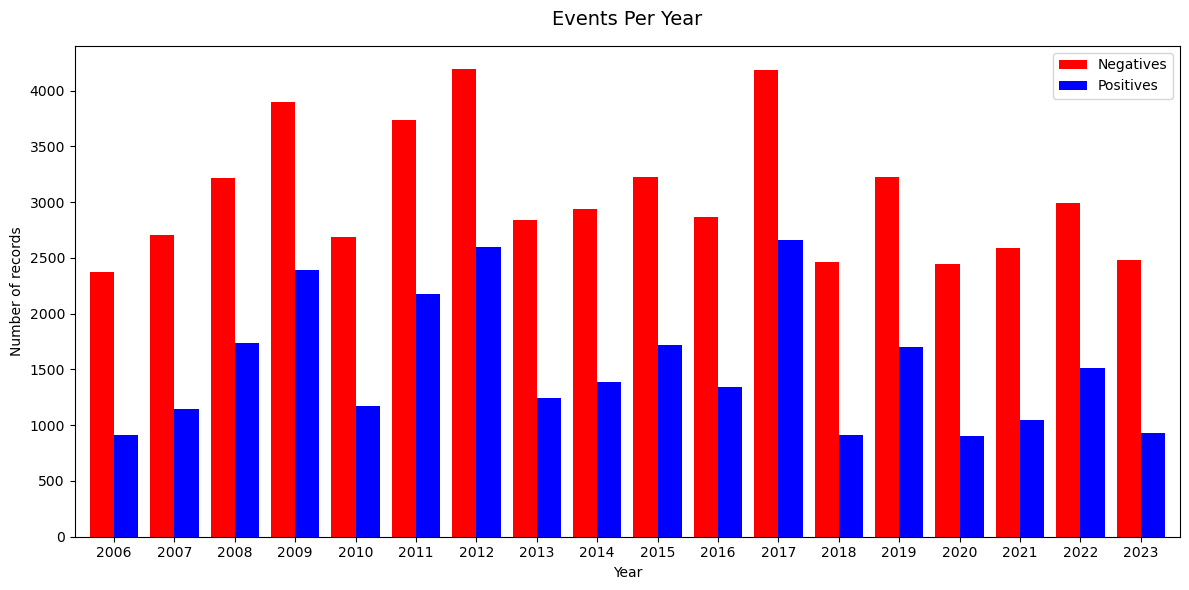

In [19]:
df_counts = full_df.groupby([full_df["date"].dt.year.rename("Year"), "fire"]).size().unstack(fill_value=0) # Positives/Negatives per year

ax = df_counts.plot(kind="bar", figsize=(12, 6), color=["red", "blue"], width=0.8)

plt.ylabel("Number of records")
plt.title("Events Per Year", fontsize=14, pad=15)
plt.legend(["Negatives", "Positives"])
plt.xticks(rotation=0)


plt.tight_layout()
plt.show()